In [1]:
import sys
print(sys.executable)
!{sys.executable} -m pip install xgboost

/opt/anaconda3/bin/python


In [2]:
import xgboost
print(xgboost.__version__)

3.4.1


In [ ]:
import sys
!{sys.executable} -m pip install xgboost --break-system-packages

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)

X_train = pd.read_csv("../data/processed/X_train_clip.csv")
X_test = pd.read_csv("../data/processed/X_test_clip.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

# scaled copy for the models that need it
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# how many healthy companies for each bankrupt one (about 20)
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Healthy per bankrupt:", round(ratio, 1))

Healthy per bankrupt: 20.2


In [5]:
# name: (model, needs_scaling)
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced"), True),
    "Ridge": (LogisticRegression(penalty="l2", C=0.01, solver="liblinear", class_weight="balanced"), True),
    "Lasso": (LogisticRegression(penalty="l1", C=0.1, solver="liblinear", class_weight="balanced"), True),
    "SVM": (SVC(kernel="rbf", class_weight="balanced"), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                                             class_weight="balanced", random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                             class_weight="balanced_subsample",
                                             random_state=42, n_jobs=-1), False),
    "XGBoost": (XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                              scale_pos_weight=ratio, eval_metric="logloss",
                              random_state=42), False),
}

In [6]:
rows = []
for name, (model, needs_scaling) in models.items():
    Xtr = X_train_s if needs_scaling else X_train
    Xte = X_test_s if needs_scaling else X_test

    model.fit(Xtr, y_train)
    pred = model.predict(Xte)

    # the "chance" score: SVM gives a distance instead of a probability
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(Xte)[:, 1]
    else:
        score = model.decision_function(Xte)

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    })
    print("done:", name)

results = pd.DataFrame(rows).set_index("Model").round(3)
results.sort_values("ROC-AUC", ascending=False)

done: Logistic Regression
done: Ridge
done: Lasso
done: SVM
done: Decision Tree
done: Random Forest
done: XGBoost


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
XGBoost,0.946,0.444,0.606,0.513,0.921
Random Forest,0.956,0.733,0.111,0.193,0.890
Decision Tree,0.691,0.113,0.808,0.198,0.799
Lasso,0.700,0.105,0.717,0.184,0.751
Ridge,0.689,0.102,0.717,0.178,0.744
Logistic Regression,0.713,0.104,0.667,0.179,0.741
SVM,0.762,0.107,0.556,0.180,0.735


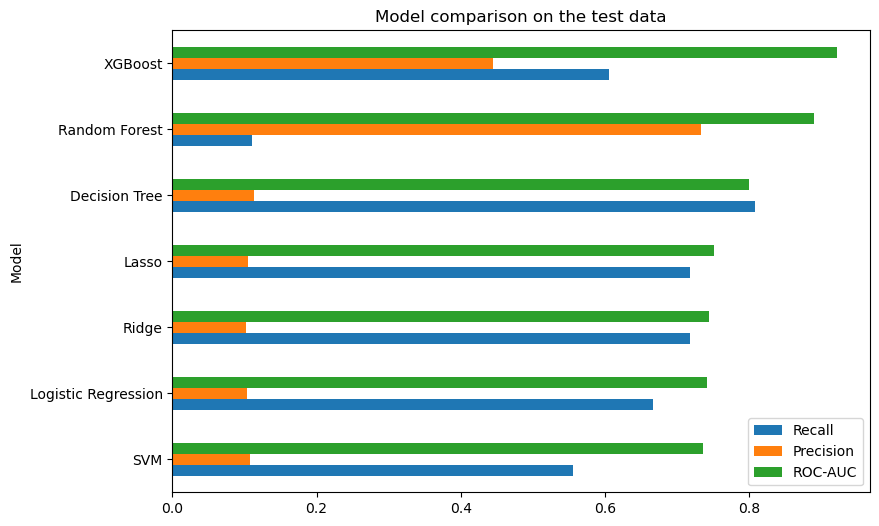

In [7]:
# One picture of the whole race
results[["Recall", "Precision", "ROC-AUC"]].sort_values("ROC-AUC").plot(
    kind="barh", figsize=(9, 6))
plt.title("Model comparison on the test data")
plt.show()
